In [2]:
!pip install pandas scikit-learn nltk spacy matplotlib

In [4]:
import pandas as pd
  

In [7]:
df = pd.read_csv(r"C:\Users\MOUNIKA\Downloads\archive (16)\Resume\Resume.csv")
df

,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR
...,...,...,...,...
2479,99416532,RANK: SGT/E-5 NON- COMMISSIONED OFFIC...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION
2480,24589765,"GOVERNMENT RELATIONS, COMMUNICATIONS ...","<div class=""fontsize fontface vmargins hmargin...",AVIATION
2481,31605080,GEEK SQUAD AGENT Professional...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION
2482,21190805,PROGRAM DIRECTOR / OFFICE MANAGER ...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION


In [8]:
print(df.shape)
df.head()

(2484, 4)


,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR


In [9]:
   df = df.sample(300, random_state=42).reset_index(drop=True)
   print(df.shape)
   print(df['Category'].value_counts())
   print(df['Resume_str'][0][:500])

(300, 4)
Category
CONSTRUCTION              20
BUSINESS-DEVELOPMENT      20
CHEF                      19
DIGITAL-MEDIA             18
ADVOCATE                  18
INFORMATION-TECHNOLOGY    18
ACCOUNTANT                17
BANKING                   15
DESIGNER                  14
APPAREL                   14
SALES                     14
CONSULTANT                13
AVIATION                  13
HEALTHCARE                13
FITNESS                   12
PUBLIC-RELATIONS          12
ENGINEERING                9
TEACHER                    8
AGRICULTURE                8
HR                         7
AUTOMOBILE                 6
ARTS                       6
FINANCE                    6
Name: count, dtype: int64
           Kpandipou    Koffi         Summary      Compassionate teaching professional delivering exemplary support and assistance to teachers and students. Display exceptional Communication and problem solving skills.  Experience in office administration and public speaking. Attentive an

In [10]:
   job_title = "IT Software Engineer"

   job_description = """
   We are looking for an IT Software Engineer with strong experience in
   python, java, sql and database management. The candidate should know
   html, css, javascript, linux, networking and git. Experience with
   cloud platforms, troubleshooting, software development, testing and
   project management is required. Good communication and teamwork skills
   are important.
   """

   print(job_title)
   print(job_description)

IT Software Engineer

We are looking for an IT Software Engineer with strong experience in
python, java, sql and database management. The candidate should know
html, css, javascript, linux, networking and git. Experience with
cloud platforms, troubleshooting, software development, testing and
project management is required. Good communication and teamwork skills
are important.



In [11]:
   import re
   import nltk
   from nltk.corpus import stopwords

   nltk.download('stopwords')
   stop_words = set(stopwords.words('english'))

   def clean_text(text):
       text = str(text).lower()                  # make all letters small
       text = re.sub(r'http\S+|www\S+', ' ', text)  # remove links
       text = re.sub(r'\S+@\S+', ' ', text)      # remove emails
       text = re.sub(r'[^a-z\s]', ' ', text)     # remove numbers and symbols
       words = [w for w in text.split() if w not in stop_words]  # remove filler words
       return " ".join(words)

   df['clean_text'] = df['Resume_str'].apply(clean_text)
   clean_jd = clean_text(job_description)

   print(df['clean_text'][0][:300])

kpandipou koffi summary compassionate teaching professional delivering exemplary support assistance teachers students display exceptional communication problem solving skills experience office administration public speaking attentive adaptable skilled management classroom operations effective levera


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\MOUNIKA\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [12]:
   skills_list = [
       "python", "java", "sql", "mysql", "oracle", "database", "html", "css",
       "javascript", "linux", "networking", "git", "cloud", "aws", "azure",
       "troubleshooting", "software development", "testing", "project management",
       "communication", "teamwork", "c++", "machine learning", "excel",
       "windows", "security", "api", "agile", "react", "node"
   ]

   def find_skills(text):
       found = []
       for skill in skills_list:
           if re.search(r'\b' + re.escape(skill) + r'\b', text):
               found.append(skill)
       return found

   df['skills'] = df['clean_text'].apply(find_skills)
   job_skills = find_skills(clean_jd)

   print("Required skills:", job_skills)
   print()
   print(df[['Category', 'skills']].head(10))

Required skills: ['python', 'java', 'sql', 'database', 'html', 'css', 'javascript', 'linux', 'networking', 'git', 'cloud', 'troubleshooting', 'software development', 'testing', 'project management', 'communication', 'teamwork']

               Category                                         skills
0               TEACHER                       [testing, communication]
1         DIGITAL-MEDIA                                             []
2          CONSTRUCTION            [project management, communication]
3                  CHEF                                             []
4               BANKING               [database, communication, excel]
5  BUSINESS-DEVELOPMENT  [project management, communication, security]
6              DESIGNER                                        [excel]
7  BUSINESS-DEVELOPMENT                                [communication]
8               TEACHER                      [communication, security]
9              DESIGNER                                      

In [13]:
   from sklearn.feature_extraction.text import TfidfVectorizer
   from sklearn.metrics.pairwise import cosine_similarity

   # Score 1: skill match
   df['matched_skills'] = df['skills'].apply(lambda s: [x for x in s if x in job_skills])
   df['missing_skills'] = df['skills'].apply(lambda s: [x for x in job_skills if x not in s])
   df['skill_score'] = df['matched_skills'].apply(len) / len(job_skills)

   # Score 2: text similarity
   vectorizer = TfidfVectorizer()
   matrix = vectorizer.fit_transform(df['clean_text'].tolist() + [clean_jd])
   df['similarity'] = cosine_similarity(matrix[-1], matrix[:-1]).flatten()

   # Final score
   df['final_score'] = 0.6 * df['skill_score'] + 0.4 * df['similarity']

   print(df[['Category', 'skill_score', 'similarity', 'final_score']].head(10))

               Category  skill_score  similarity  final_score
0               TEACHER     0.117647    0.030348     0.082727
1         DIGITAL-MEDIA     0.000000    0.013854     0.005542
2          CONSTRUCTION     0.117647    0.069952     0.098569
3                  CHEF     0.000000    0.005836     0.002334
4               BANKING     0.117647    0.038264     0.085894
5  BUSINESS-DEVELOPMENT     0.117647    0.049160     0.090252
6              DESIGNER     0.000000    0.010634     0.004254
7  BUSINESS-DEVELOPMENT     0.058824    0.016659     0.041958
8               TEACHER     0.058824    0.015059     0.041318
9              DESIGNER     0.000000    0.003822     0.001529


In [14]:
   ranked = df.sort_values('final_score', ascending=False).reset_index(drop=True)
   ranked['Rank'] = ranked.index + 1
   ranked['Score_%'] = (ranked['final_score'] * 100).round(1)

   top10 = ranked[['Rank', 'ID', 'Category', 'Score_%', 'matched_skills', 'missing_skills']].head(10)
   top10

,Rank,ID,Category,Score_%,matched_skills,missing_skills
0,1,24643412,CONSULTANT,42.3,"[java, sql, database, html, javascript, linux,...","[python, css, networking, git, cloud, communic..."
1,2,17823436,BANKING,41.0,"[java, sql, database, html, linux, cloud, trou...","[python, css, javascript, networking, git, pro..."
2,3,10089434,INFORMATION-TECHNOLOGY,39.8,"[java, sql, database, html, css, linux, networ...","[python, javascript, git, software development..."
3,4,23464505,AVIATION,37.7,"[java, sql, database, html, css, linux, git, s...","[python, javascript, networking, cloud, troubl..."
4,5,36434348,INFORMATION-TECHNOLOGY,35.6,"[sql, database, html, troubleshooting, softwar...","[python, java, css, javascript, linux, network..."
5,6,98300955,HEALTHCARE,35.5,"[java, sql, database, html, css, javascript, l...","[python, networking, git, cloud, troubleshooti..."
6,7,22232367,AVIATION,32.7,"[python, sql, database, linux, networking, tro...","[java, html, css, javascript, git, cloud, soft..."
7,8,17641670,INFORMATION-TECHNOLOGY,32.7,"[html, networking, cloud, troubleshooting, tes...","[python, java, sql, database, css, javascript,..."
8,9,46260230,INFORMATION-TECHNOLOGY,28.8,"[database, linux, networking, troubleshooting,...","[python, java, sql, html, css, javascript, git..."
9,10,19090468,HEALTHCARE,28.0,"[java, database, linux, networking, cloud, tro...","[python, sql, html, css, javascript, git, soft..."


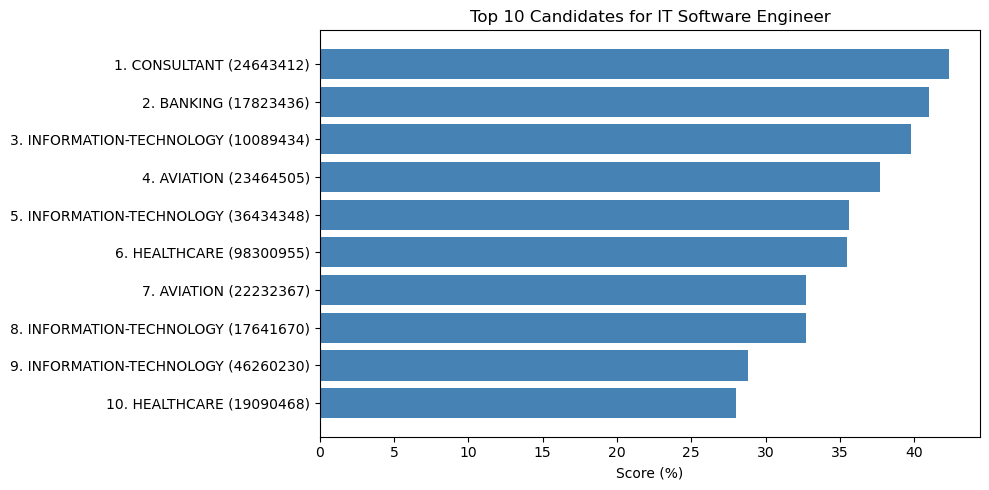

In [15]:
   import matplotlib.pyplot as plt

   top = ranked.head(10)
   labels = top['Rank'].astype(str) + ". " + top['Category'] + " (" + top['ID'].astype(str) + ")"

   plt.figure(figsize=(10, 5))
   plt.barh(labels[::-1], top['Score_%'][::-1], color='steelblue')
   plt.xlabel("Score (%)")
   plt.title("Top 10 Candidates for IT Software Engineer")
   plt.tight_layout()
   plt.savefig("top10_candidates.png")
   plt.show()

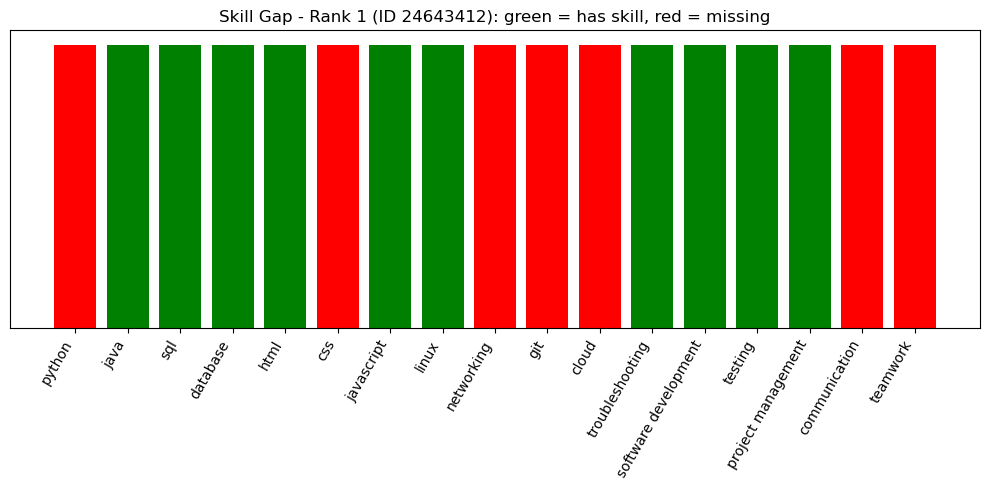

Matched skills: ['java', 'sql', 'database', 'html', 'javascript', 'linux', 'troubleshooting', 'software development', 'testing', 'project management']
Missing skills: ['python', 'css', 'networking', 'git', 'cloud', 'communication', 'teamwork']


In [16]:
   best = ranked.iloc[0]

   has = [1 if s in best['matched_skills'] else 0 for s in job_skills]
   colors = ['green' if h == 1 else 'red' for h in has]

   plt.figure(figsize=(10, 5))
   plt.bar(job_skills, [1]*len(job_skills), color=colors)
   plt.xticks(rotation=60, ha='right')
   plt.yticks([])
   plt.title(f"Skill Gap - Rank 1 (ID {best['ID']}): green = has skill, red = missing")
   plt.tight_layout()
   plt.savefig("skill_gap_rank1.png")
   plt.show()

   print("Matched skills:", best['matched_skills'])
   print("Missing skills:", best['missing_skills'])

# Resume Screening System: How It Works

## Job we screened for
IT Software Engineer. The system compared 300 resumes against this job description.

## How a resume is scored
Each resume gets a score from 0 to 100% made of two parts:
- **Skill match (60% of the score):** How many of the 17 required skills (such as Java, SQL, Linux, Git) appear in the resume.
- **Text similarity (40% of the score):** How close the overall wording of the resume is to the job description.

Final score = 0.6 x skill match + 0.4 x text similarity

## Why some candidates rank higher
Candidates rank higher when they mention more of the required skills and their resume uses language similar to the job description. The top candidate (ID 24643412) scored 42.3% because the resume shows 10 of the 17 required skills, including Java, SQL, Linux and project management.

## What skills are missing
For every candidate the system lists the required skills that are missing. The top candidate is missing Python, CSS, networking, Git, cloud, communication and teamwork. A recruiter can use this to decide who to interview and what to ask about.

## Notes and limitations
- The system ranks by skills found in the text, not by the candidate's job category. Some non-IT resumes rank high because they mention technical skills.
- Skills are found by matching words from a fixed skills list, so a skill written in a different way may be missed.
- The score is a decision-support tool. A human recruiter should make the final decision.

In [17]:
   output = ranked[['Rank', 'ID', 'Category', 'Score_%', 'skill_score', 'similarity']].copy()
   output['Matched_Skills'] = ranked['matched_skills'].apply(lambda s: ", ".join(s))
   output['Missing_Skills'] = ranked['missing_skills'].apply(lambda s: ", ".join(s))

   output.to_csv("candidate_ranking.csv", index=False)

   # Also save the skills list used
   import pandas as pd
   pd.DataFrame({'skill': skills_list}).to_csv("skills.csv", index=False)

   print("Saved!", output.shape)
   output.head()

Saved! (300, 8)


,Rank,ID,Category,Score_%,skill_score,similarity,Matched_Skills,Missing_Skills
0,1,24643412,CONSULTANT,42.3,0.588235,0.174904,"java, sql, database, html, javascript, linux, ...","python, css, networking, git, cloud, communica..."
1,2,17823436,BANKING,41.0,0.588235,0.143786,"java, sql, database, html, linux, cloud, troub...","python, css, javascript, networking, git, proj..."
2,3,10089434,INFORMATION-TECHNOLOGY,39.8,0.588235,0.112788,"java, sql, database, html, css, linux, network...","python, javascript, git, software development,..."
3,4,23464505,AVIATION,37.7,0.529412,0.147449,"java, sql, database, html, css, linux, git, so...","python, javascript, networking, cloud, trouble..."
4,5,36434348,INFORMATION-TECHNOLOGY,35.6,0.470588,0.184256,"sql, database, html, troubleshooting, software...","python, java, css, javascript, linux, networki..."


In [18]:
   readme = """# FUTURE_ML_03 - Resume / Candidate Screening System

   An NLP-based system that screens, scores and ranks resumes against a job description, and shows which required skills each candidate is missing.

   ## Problem
   Hiring teams receive hundreds of resumes for one role. Reading them all by hand is slow and inconsistent. This project automates the first screening step.

   ## Dataset
   Kaggle Resume Dataset (snehaanbhawal). 300 random resumes were used.
   Link: https://www.kaggle.com/datasets/snehaanbhawal/resume-dataset

   ## Job role used
   IT Software Engineer (17 required skills such as Python, Java, SQL, Linux, Git, cloud, communication).

   ## Approach
   1. Clean the resume text (lowercase, remove links, emails, symbols, stopwords).
   2. Extract skills by matching against a skills list (skills.csv).
   3. Score each resume:
      - Skill match (60%): share of required skills found in the resume.
      - Text similarity (40%): TF-IDF cosine similarity with the job description.
      - Final score = 0.6 x skill match + 0.4 x text similarity.
   4. Rank candidates from highest to lowest score.
   5. Identify the skill gap: required skills missing from each resume.

   ## Results
   - The top candidate scored 42.3% and matched 10 of 17 required skills.
   - The ranking is saved in candidate_ranking.csv with matched and missing skills for every candidate.
   - Charts: top10_candidates.png and skill_gap_rank1.png.

   ## Files
   - resume_screening.ipynb : full code and explanation
   - candidate_ranking.csv : ranked list of all 300 candidates
   - skills.csv : skills list used for extraction
   - top10_candidates.png, skill_gap_rank1.png : charts
   - requirements.txt : libraries needed

   ## How to run
   1. Download Resume.csv from the Kaggle link above.
   2. Install the libraries: pip install -r requirements.txt
   3. Open resume_screening.ipynb in Jupyter Notebook and update the path to Resume.csv.
   4. Run all cells.

   ## Limitations
   - Skills are found by matching words from a fixed list, so skills written differently may be missed.
   - The system ranks by skills found, not by job category, so some non-IT resumes can rank high.
   - It supports a human recruiter and should not replace the final decision.

   ## Tools
   Python, pandas, NLTK, scikit-learn, matplotlib, Jupyter Notebook
   """

   with open("README.md", "w", encoding="utf-8") as f:
       f.write(readme)

   with open("requirements.txt", "w") as f:
       f.write("pandas\nnumpy\nscikit-learn\nnltk\nspacy\nmatplotlib\n")

   print("README.md and requirements.txt created")

README.md and requirements.txt created
